<!-- WARNING: THIS FILE WAS AUTOGENERATED! DO NOT EDIT! -->

## Torch

In [0]:
#| echo: false
#| output: asis
show_doc(WarmupCosineSchedule)

---

[source](https://github.com/benmfox/wavefm/blob/main/wavefm/jepa.py#L31){target="_blank" style="float:right; font-size:smaller"}

### WarmupCosineSchedule

```python

def WarmupCosineSchedule(
    optimizer, warmup_steps, start_lr, ref_lr, T_max, last_epoch:int=-1, final_lr:float=0.0, warmup:NoneType=None
):


```

*Initialize self.  See help(type(self)) for accurate signature.*

In [0]:
#| echo: false
#| output: asis
show_doc(generate_block_masks)

---

[source](https://github.com/benmfox/wavefm/blob/main/wavefm/jepa.py#L283){target="_blank" style="float:right; font-size:smaller"}

### generate_block_masks

```python

def generate_block_masks(
    x, patch_size, patch_stride, context_ratio_range, target_ratio_range, min_block_size, max_block_size,
    melt_channels_to_batch:bool=False, return_nested:bool=True
):


```

*Generates block masks for time series data.*

Args:
    x: tensor of time series data.
    patch_size: Size of each patch.
    patch_stride: Stride of the patches.
    context_ratio_range: Tuple indicating the min and max ratio of context patches.
    target_ratio_range: Tuple indicating the min and max ratio of target patches.
    min_block_size: Minimum size of a block.
    max_block_size: Maximum size of a block (defaults to 25% of num_patches).
    return_nested: Whether to return nested tensors or 0 padded tensors.
Returns:
    masks (target_masks): Tensor of target indices for each sequence in the batch.
    non_masks (context_masks): Tensor of context indices for each sequence in the batch.

In [0]:
#| echo: false
#| output: asis
show_doc(create_masks_around_targets)

---

[source](https://github.com/benmfox/wavefm/blob/main/wavefm/jepa.py#L204){target="_blank" style="float:right; font-size:smaller"}

### create_masks_around_targets

```python

def create_masks_around_targets(
    bs, num_patches, max_context_distance:int=10, target_mask_range:tuple=(0.05, 0.25),
    context_mask_range:tuple=(0.5, 1.0)
):


```

*Creates different masks for each batch item, with consistent sizes.*

Args:
    bs: Batch size
    num_patches: Number of patches in sequence
    max_context_distance: Maximum distance between a target and its context patches
    target_ratio_range: Range for ratio of patches to use as targets
    context_ratio_range: Range for ratio of context to select from available context

Returns:
    mask_indices: Target patch indices [bs, num_targets]
    non_mask_indices: Context patch indices [bs, num_context]

In [0]:
#| echo: false
#| output: asis
show_doc(create_masks)

---

[source](https://github.com/benmfox/wavefm/blob/main/wavefm/jepa.py#L132){target="_blank" style="float:right; font-size:smaller"}

### create_masks

```python

def create_masks(
    x, patch_size, patch_stride, context_mask_range, target_mask_range, melt_channels_to_batch:bool=False,
    return_nested:bool=False
):


```

In [0]:
#| echo: false
#| output: asis
show_doc(apply_masks)

---

[source](https://github.com/benmfox/wavefm/blob/main/wavefm/jepa.py#L113){target="_blank" style="float:right; font-size:smaller"}

### apply_masks

```python

def apply_masks(
    x, masks
):


```

In [0]:
#| echo: false
#| output: asis
show_doc(JEPABlock)

---

[source](https://github.com/benmfox/wavefm/blob/main/wavefm/jepa.py#L68){target="_blank" style="float:right; font-size:smaller"}

### JEPABlock

```python

def JEPABlock(
    dim, num_heads, mlp_ratio:float=4.0, qkv_bias:bool=False, qk_scale:NoneType=None, drop:float=0.0,
    attn_drop:float=0.0, act_layer:type=GELU, norm_layer:type=LayerNorm, rotary_pes:bool=False
):


```

*Base class for all neural network modules.*

Your models should also subclass this class.

Modules can also contain other Modules, allowing them to be nested in
a tree structure. You can assign the submodules as regular attributes::

    import torch.nn as nn
    import torch.nn.functional as F

    class Model(nn.Module):
        def __init__(self) -> None:
            super().__init__()
            self.conv1 = nn.Conv2d(1, 20, 5)
            self.conv2 = nn.Conv2d(20, 20, 5)

        def forward(self, x):
            x = F.relu(self.conv1(x))
            return F.relu(self.conv2(x))

Submodules assigned in this way will be registered, and will also have their
parameters converted when you call :meth:`to`, etc.

.. note::
    As per the example above, an ``__init__()`` call to the parent class
    must be made before assignment on the child.

:ivar training: Boolean represents whether this module is in training or
                evaluation mode.
:vartype training: bool

In [ ]:
max_len = 5000
batch_size = 2
seq_lens = torch.randint(4000, max_len, (batch_size,))

# Create input tensors with different sequence lengths
x_list = [torch.randn(7, length) for length in seq_lens]
x_nested = torch.nested.as_nested_tensor(x_list, layout=torch.jagged)
x = torch.randn(2, 7, 5000)
#masks, non_masks = generate_block_masks(x_nested, 10, 10, (0.05, 0.08), (0.05, 0.1), min_block_size=1, max_block_size = 2, return_nested=False)
masks, non_masks = create_masks(x_nested, 10, 10, (0.05, 0.08), (0.0, 0.1), melt_channels_to_batch=True, return_nested=True)
#[i.shape for i in masks], torch.numel(non_masks)
#print([(i,y) for i,y  in zip(masks, non_masks)])    
masks.shape

torch.Size([14, j94])

In [0]:
#| echo: false
#| output: asis
show_doc(Encoder)

---

[source](https://github.com/benmfox/wavefm/blob/main/wavefm/jepa.py#L401){target="_blank" style="float:right; font-size:smaller"}

### Encoder

```python

def Encoder(
    c_in, num_patches, patch_size, patch_stride, d_model, nhead, num_layers, use_tst_block:bool=False,
    shared_embedding:bool=True, pe_type:str='tAPE', mlp_ratio:float=4.0, qkv_bias:bool=True, qk_scale:NoneType=None,
    drop_rate:float=0.0, attn_drop_rate:float=0.0, norm_layer:type=LayerNorm, jepa:bool=True,
    embed_activation:GELU=GELU(approximate='none'), init_std:float=0.02, tokenizer_type:str='simple',
    tokenizer_kwargs:dict={}
):


```

*Base class for all neural network modules.*

Your models should also subclass this class.

Modules can also contain other Modules, allowing them to be nested in
a tree structure. You can assign the submodules as regular attributes::

    import torch.nn as nn
    import torch.nn.functional as F

    class Model(nn.Module):
        def __init__(self) -> None:
            super().__init__()
            self.conv1 = nn.Conv2d(1, 20, 5)
            self.conv2 = nn.Conv2d(20, 20, 5)

        def forward(self, x):
            x = F.relu(self.conv1(x))
            return F.relu(self.conv2(x))

Submodules assigned in this way will be registered, and will also have their
parameters converted when you call :meth:`to`, etc.

.. note::
    As per the example above, an ``__init__()`` call to the parent class
    must be made before assignment on the child.

:ivar training: Boolean represents whether this module is in training or
                evaluation mode.
:vartype training: bool

In [ ]:
enc_model = Encoder(
            c_in=7,
            num_patches=500,
            patch_size=10,
            patch_stride=10,
            d_model=128,
            nhead=2,
            num_layers=1,
            mlp_ratio=4.0,
            qkv_bias=True,
            qk_scale=None,
            drop_rate=0.0,
            attn_drop_rate=0.0,
            norm_layer=nn.LayerNorm,
            jepa=True,
            embed_activation=nn.GELU(),
            tokenizer_type='simple',
            pe_type = 'tAPE',
            use_tst_block=True,
            shared_embedding=False,
            )
batch_size = 2
n_vars = 7
max_len = 5000
x = torch.randn(batch_size, n_vars, max_len)

seq_lens = torch.randint(500, max_len, (batch_size,))

# Create input tensors with different sequence lengths
x_list = [torch.randn(n_vars, length) for length in seq_lens]
x_nested = torch.nested.as_nested_tensor(x_list, layout=torch.jagged)
masks, non_masks = create_masks(x_nested, patch_size=10, patch_stride=10, context_mask_range=[0.1,0.1], target_mask_range=[0.1,0.1], melt_channels_to_batch=True, return_nested=True)#generate_block_masks(x=x, patch_size=self.patch_size, patch_stride=self.patch_stride, context_ratio_range=self.context_mask_range, target_ratio_range=self.target_mask_range, min_block_size=self.mask_block_range[0], max_block_size=self.mask_block_range[1], melt_channels_to_batch=self.melt_channels_to_batch, return_nested=x.is_nested)
#print(masks.shape, non_masks.shape)
#print([i.shape for i in x_nested.unbind()])
#print([i for i in masks.unbind()], [i.shape for i in non_masks.unbind()])
enc_model(x_nested, mask=non_masks)

/opt/miniconda3/envs/timeflies/lib/python3.12/site-packages/torch/nested/__init__.py:109: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/aten/src/ATen/NestedTensorImpl.cpp:182.)
  return torch._nested_tensor_from_tensor_list(ts, dtype, None, device, None)


NestedTensor(size=(14, j17, 128), offsets=tensor([  0,  34,  68, 102, 136, 170, 204, 238, 244, 250, 256, 262, 268, 274,
        280]), grad_fn=<NativeLayerNormBackward0 object>, contiguous=True)

In [ ]:
import matplotlib.pyplot as plt
d_model = 512
predictor_embed_dim = 32
num_patches = 14400

omega_pred = np.arange(predictor_embed_dim // 2, dtype=float)
omega_pred /= predictor_embed_dim / 2.0
omega_pred = 1.0 / 10000**omega_pred

pos = np.arange(num_patches, dtype=float)
pos = pos.reshape(-1)
out = np.einsum("m,d->md", pos, omega_pred)

emb_sin = np.sin(out)
emb_cos = np.cos(out)

emb_pred = np.concatenate([emb_sin, emb_cos], axis=1)

omega = np.arange(d_model // 2, dtype=float)
omega /= d_model / 2.0
omega = 1.0 / 10000**omega

pos = np.arange(num_patches, dtype=float)
pos = pos.reshape(-1)
out = np.einsum("m,d->md", pos, omega)

emb_sin = np.sin(out)
emb_cos = np.cos(out)

emb = np.concatenate([emb_sin, emb_cos], axis=1)

[<matplotlib.lines.Line2D>]

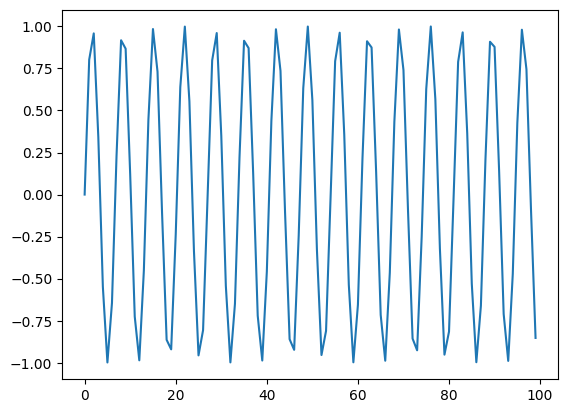

In [ ]:
plt.plot(emb[:100, 2])

[<matplotlib.lines.Line2D>]

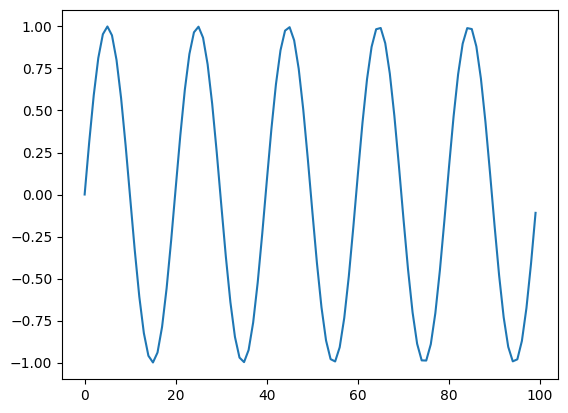

In [ ]:
plt.plot(emb_pred[:100, 2])

In [ ]:
pos = torch.arange(0, num_patches, dtype=torch.float).unsqueeze(1)
div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))
W_pos = torch.zeros(num_patches, d_model)
W_pos[:, 0::2] = torch.sin((pos * div_term)*(d_model/num_patches)) # this is the difference between normal PE and tAPE, scaling (d_model/seq_len)
W_pos[:, 1::2] = torch.cos((pos * div_term)*(d_model/num_patches))

pos = torch.arange(0, num_patches, dtype=torch.float).unsqueeze(1)
div_term = torch.exp(torch.arange(0, predictor_embed_dim, 2).float() * (-np.log(10000.0) / predictor_embed_dim))
W_pos_pred = torch.zeros(num_patches, predictor_embed_dim)
W_pos_pred[:, 0::2] = torch.sin((pos * div_term)*(predictor_embed_dim/num_patches)) # this is the difference between normal PE and tAPE, scaling (d_model/seq_len)
W_pos_pred[:, 1::2] = torch.cos((pos * div_term)*(predictor_embed_dim/num_patches))

[<matplotlib.lines.Line2D>]

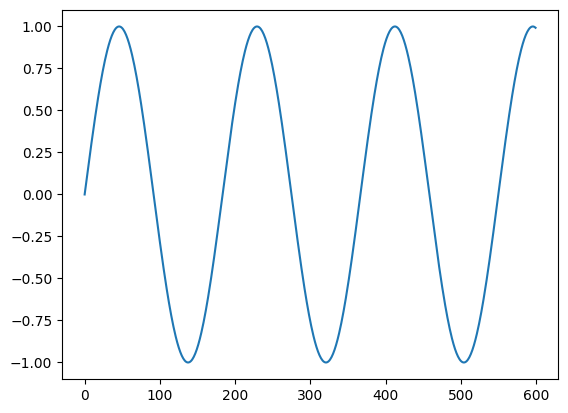

In [ ]:
plt.plot(W_pos[:600, 2].numpy())

[<matplotlib.lines.Line2D>]

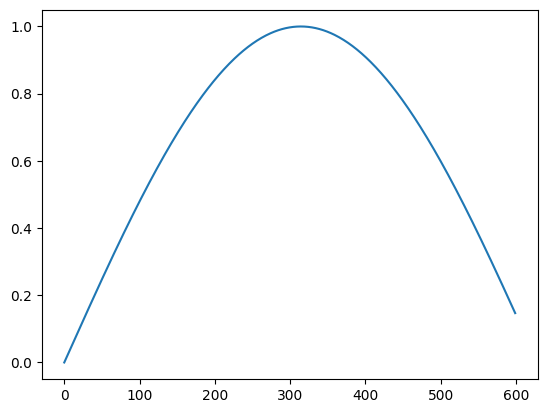

In [ ]:
plt.plot(W_pos_pred[:600, 2].numpy())

In [0]:
#| echo: false
#| output: asis
show_doc(mse_variance_loss)

---

[source](https://github.com/benmfox/wavefm/blob/main/wavefm/jepa.py#L918){target="_blank" style="float:right; font-size:smaller"}

### mse_variance_loss

```python

def mse_variance_loss(
    pred, target_ema, representations, alpha:float=0.2
):


```

In [0]:
#| echo: false
#| output: asis
show_doc(loss_pred)

---

[source](https://github.com/benmfox/wavefm/blob/main/wavefm/jepa.py#L887){target="_blank" style="float:right; font-size:smaller"}

### loss_pred

```python

def loss_pred(
    pred, target_ema, representations:NoneType=None, alpha:float=0.2
):


```

*Compute MSE loss between predictions and targets.*

Args:
    pred: Predictions [nested tensor or regular tensor]
    target_ema: Target embeddings from EMA encoder
    representations: Optional context representations (unused currently)
    alpha: Weight for variance loss (unused currently)

Returns:
    Scalar loss value

In [0]:
#| echo: false
#| output: asis
show_doc(variance_loss)

---

[source](https://github.com/benmfox/wavefm/blob/main/wavefm/jepa.py#L877){target="_blank" style="float:right; font-size:smaller"}

### variance_loss

```python

def variance_loss(
    x
):


```

In [0]:
#| echo: false
#| output: asis
show_doc(Predictor)

---

[source](https://github.com/benmfox/wavefm/blob/main/wavefm/jepa.py#L612){target="_blank" style="float:right; font-size:smaller"}

### Predictor

```python

def Predictor(
    num_patches, encoder_embed_dim:int=128, predictor_embed_dim:int=128, nhead:int=2, num_layers:int=1,
    use_tst_block:bool=False, pe_type:str='tAPE', mlp_ratio:float=4.0, qkv_bias:bool=True, qk_scale:NoneType=None,
    drop_rate:float=0.0, attn_drop_rate:float=0.0, norm_layer:type=LayerNorm,
    embed_activation:GELU=GELU(approximate='none'), init_std:float=0.02,
    c_in_mask_tokens:int=1, # number of channels in the encoder (if treating channels sep)
    shuffle:bool=True
):


```

*Base class for all neural network modules.*

Your models should also subclass this class.

Modules can also contain other Modules, allowing them to be nested in
a tree structure. You can assign the submodules as regular attributes::

    import torch.nn as nn
    import torch.nn.functional as F

    class Model(nn.Module):
        def __init__(self) -> None:
            super().__init__()
            self.conv1 = nn.Conv2d(1, 20, 5)
            self.conv2 = nn.Conv2d(20, 20, 5)

        def forward(self, x):
            x = F.relu(self.conv1(x))
            return F.relu(self.conv2(x))

Submodules assigned in this way will be registered, and will also have their
parameters converted when you call :meth:`to`, etc.

.. note::
    As per the example above, an ``__init__()`` call to the parent class
    must be made before assignment on the child.

:ivar training: Boolean represents whether this module is in training or
                evaluation mode.
:vartype training: bool

In [ ]:
x = torch.randn(6)
ids_og = torch.argsort(x)
x_shuffled = torch.randperm(len(x))
ids_restore = torch.argsort(x_shuffled)
x_s = x[x_shuffled]
x, x_shuffled, ids_restore, x_s, x_s[ids_restore],# x_s[]#, torch.gather(x_s, dim=0, index = x_shuffled)

(tensor([-0.0847,  0.5606, -0.6734,  1.0109, -0.3516, -0.4074]),
 tensor([4, 5, 1, 3, 0, 2]),
 tensor([4, 2, 5, 3, 0, 1]),
 tensor([-0.3516, -0.4074,  0.5606,  1.0109, -0.0847, -0.6734]),
 tensor([-0.0847,  0.5606, -0.6734,  1.0109, -0.3516, -0.4074]))

In [ ]:
predictor = Predictor(
    num_patches=500,
    encoder_embed_dim=128,
    predictor_embed_dim=128,
    nhead=2,
    num_layers=1,
    pe_type='tAPE',
    c_in_mask_tokens=7,
)

batch_size = 2
n_vars = 7
max_len = 5000
x = torch.randn(batch_size, n_vars, max_len)

seq_lens = torch.randint(4000, max_len, (batch_size,))

# Create input tensors with different sequence lengths
x_list = [torch.randn(n_vars, length) for length in seq_lens]
x_nested = torch.nested.as_nested_tensor(x_list, layout=torch.jagged)

masks, non_masks = create_masks(x_nested, patch_size=10, patch_stride=10, context_mask_range=[0.1,0.1], target_mask_range=[0.1,0.1], melt_channels_to_batch=True, return_nested=True)#generate_block_masks(x=x, patch_size=self.patch_size, patch_stride=self.patch_stride, context_ratio_range=self.context_mask_range, target_ratio_range=self.target_mask_range, min_block_size=self.mask_block_range[0], max_block_size=self.mask_block_range[1], melt_channels_to_batch=self.melt_channels_to_batch, return_nested=x.is_nested)

encoded_vals = enc_model(x, mask=non_masks)
print(encoded_vals.shape)
r = predictor(encoded_vals, mask=masks, non_masks=non_masks)
print([i.shape for i in r], [i.shape for i in masks])

torch.Size([2, j141, 128])


IndexError: index 0 is out of bounds for dimension 0 with size 0

In [0]:
#| echo: false
#| output: asis
show_doc(JEPASimpleLightning)

---

[source](https://github.com/benmfox/wavefm/blob/main/wavefm/jepa.py#L927){target="_blank" style="float:right; font-size:smaller"}

### JEPASimpleLightning

```python

def JEPASimpleLightning(
    learning_rate, train_size, batch_size, n_gpus, patchtsjepa_encoder_kwargs, patchtsjepa_predictor_kwargs,
    num_nodes:int=1, weight_decay:float=0.04, use_weight_decay_scheduler:bool=False, final_weight_decay:float=0.4,
    epochs:int=100, optimizer_type:str='adamw', scheduler_type:str='OneCycle',
    target_mask_range:tuple=(0.05, 0.3), # the target can be up to 50% of the original x
    context_mask_range:tuple=(0.5, 1.0), # the context can be up to 80% of masked out target (1-target_mask_ratio)
    mask_block_range:tuple=(1, 30), ema_decay:float=0.996, scheduler_kwargs:dict={}, transforms:NoneType=None,
    loss_fn:function=loss_pred, linear_probe:bool=False
):


```

*Hooks to be used in LightningModule.*

In [ ]:
encoder_kwargs = dict(
         c_in=7,
            num_patches=30,
            patch_size=128,
            patch_stride = 128,
            d_model=512,
            nhead=8,
            num_layers=3,
            mlp_ratio=4.0,
            qkv_bias=True,
            qk_scale=None,
            drop_rate=0.0,
            attn_drop_rate=0.0,
            norm_layer=nn.LayerNorm,
            jepa=True,
            embed_activation=nn.GELU(),
            tokenizer_type='linear',
            pe_type='tAPE',
            tokenizer_kwargs=dict(bottleneck_channels = 32, kernel_size=64, depth=1, residual = True, bottleneck=True),
            use_tst_block=True,
            shared_embedding=False,
)

predictor_kwargs = dict(num_patches=30,
    encoder_embed_dim=512,
    predictor_embed_dim=128,
    nhead=4,
    pe_type='tAPE',
    num_layers=2,)

jepa_lightning = JEPASimpleLightning(
    learning_rate=0.001,
    train_size=1000,
    batch_size=10,
    mask_block_range=(1, 1),
    n_gpus=1,
    patchtsjepa_encoder_kwargs=encoder_kwargs,
    patchtsjepa_predictor_kwargs=predictor_kwargs,
    linear_probe=True,
)

x = (torch.randn(2, 7, 128*30), None)

batch_size = 2
n_vars = 7
max_len = 128*30

seq_lens = torch.randint(128*20, max_len, (batch_size,))

# Create input tensors with different sequence lengths
x_list = [torch.randn(n_vars, length) for length in seq_lens]
x_nested = torch.nested.as_nested_tensor(x_list, layout=torch.jagged)
print(x_nested.shape)
#o = jepa_lightning(x_nested)
x = (x_nested, None)
o = jepa_lightning.validation_step(x, 0)
# #from pytorch_lightning.utilities.model_summary import summarize

# summarize(jepa_lightning)

torch.Size([2, 7, j140])


AttributeError: 'NoneType' object has no attribute 'cpu'

## LeJEPA

In [ ]:
# import timm, torch
# from torchvision.ops import MLP as VisionMLP
# from torch import nn
# class ViTEncoder(nn.Module):
#     def __init__(self, proj_dim=128):
#         super().__init__()
#         self.backbone = timm.create_model(
#             "vit_small_patch8_224",
#             pretrained=False,
#             num_classes=512,
#             drop_path_rate=0.1,
#             img_size=128,
#         )
#         self.proj = VisionMLP(512, [2048, 2048, proj_dim], norm_layer=nn.BatchNorm1d)

#     def forward(self, x):
    
#         N, V = x.shape[:2]
#         emb = self.backbone(x.flatten(0, 1))
#         return emb, self.proj(emb).reshape(N, V, -1).transpose(0, 1)
# t = ViTEncoder()
# x = torch.randn(3, 4, 3, 128, 128)
# emb, proj = t(x)
# s = SIGReg()
# print(emb.shape, proj.shape)
# stat = s(proj)

# stat

torch.Size([12, 512]) torch.Size([4, 3, 128])
torch.Size([128, 256])
torch.Size([128, 256])
torch.Size([4, 3, 256, 17])
torch.Size([4, 256, 17])
torch.Size([4, 256])


tensor(1.1209, grad_fn=<MeanBackward0>)

In [0]:
#| echo: false
#| output: asis
show_doc(MultimodalSIGReg)

---

[source](https://github.com/benmfox/wavefm/blob/main/wavefm/jepa.py#L1417){target="_blank" style="float:right; font-size:smaller"}

### MultimodalSIGReg

```python

def MultimodalSIGReg(
    knots:int=17, num_slices:int=256, prior_type:str='laplace'
):


```

*Base class for all neural network modules.*

Your models should also subclass this class.

Modules can also contain other Modules, allowing them to be nested in
a tree structure. You can assign the submodules as regular attributes::

    import torch.nn as nn
    import torch.nn.functional as F

    class Model(nn.Module):
        def __init__(self) -> None:
            super().__init__()
            self.conv1 = nn.Conv2d(1, 20, 5)
            self.conv2 = nn.Conv2d(20, 20, 5)

        def forward(self, x):
            x = F.relu(self.conv1(x))
            return F.relu(self.conv2(x))

Submodules assigned in this way will be registered, and will also have their
parameters converted when you call :meth:`to`, etc.

.. note::
    As per the example above, an ``__init__()`` call to the parent class
    must be made before assignment on the child.

:ivar training: Boolean represents whether this module is in training or
                evaluation mode.
:vartype training: bool

In [0]:
#| echo: false
#| output: asis
show_doc(LeJEPALightning)

---

[source](https://github.com/benmfox/wavefm/blob/main/wavefm/jepa.py#L1538){target="_blank" style="float:right; font-size:smaller"}

### LeJEPALightning

```python

def LeJEPALightning(
    learning_rate, train_size, batch_size, n_gpus, patchtsjepa_encoder_kwargs, num_nodes:int=1,
    weight_decay:float=0.04, use_weight_decay_scheduler:bool=False, final_weight_decay:float=0.4, epochs:int=100,
    optimizer_type:str='adamw', scheduler_type:str='OneCycle', scheduler_kwargs:dict={},
    context_mask_range:tuple=(0.2, 0.8), # how many tokens to keep per channel batch?
    transforms:NoneType=None, # important for LeJEPA!
    lambda_reg:float=0.05, num_slices:int=256
):


```

*Hooks to be used in LightningModule.*

In [0]:
#| echo: false
#| output: asis
show_doc(LeJEPAEncoder)

---

[source](https://github.com/benmfox/wavefm/blob/main/wavefm/jepa.py#L1522){target="_blank" style="float:right; font-size:smaller"}

### LeJEPAEncoder

```python

def LeJEPAEncoder(
    hidden_size:int=2048, proj_dim:int=512, encoder_kwargs:VAR_KEYWORD
):


```

*Base class for all neural network modules.*

Your models should also subclass this class.

Modules can also contain other Modules, allowing them to be nested in
a tree structure. You can assign the submodules as regular attributes::

    import torch.nn as nn
    import torch.nn.functional as F

    class Model(nn.Module):
        def __init__(self) -> None:
            super().__init__()
            self.conv1 = nn.Conv2d(1, 20, 5)
            self.conv2 = nn.Conv2d(20, 20, 5)

        def forward(self, x):
            x = F.relu(self.conv1(x))
            return F.relu(self.conv2(x))

Submodules assigned in this way will be registered, and will also have their
parameters converted when you call :meth:`to`, etc.

.. note::
    As per the example above, an ``__init__()`` call to the parent class
    must be made before assignment on the child.

:ivar training: Boolean represents whether this module is in training or
                evaluation mode.
:vartype training: bool

In [0]:
#| echo: false
#| output: asis
show_doc(SIGReg)

---

[source](https://github.com/benmfox/wavefm/blob/main/wavefm/jepa.py#L1480){target="_blank" style="float:right; font-size:smaller"}

### SIGReg

```python

def SIGReg(
    knots:int=17, num_slices:int=256
):


```

*Base class for all neural network modules.*

Your models should also subclass this class.

Modules can also contain other Modules, allowing them to be nested in
a tree structure. You can assign the submodules as regular attributes::

    import torch.nn as nn
    import torch.nn.functional as F

    class Model(nn.Module):
        def __init__(self) -> None:
            super().__init__()
            self.conv1 = nn.Conv2d(1, 20, 5)
            self.conv2 = nn.Conv2d(20, 20, 5)

        def forward(self, x):
            x = F.relu(self.conv1(x))
            return F.relu(self.conv2(x))

Submodules assigned in this way will be registered, and will also have their
parameters converted when you call :meth:`to`, etc.

.. note::
    As per the example above, an ``__init__()`` call to the parent class
    must be made before assignment on the child.

:ivar training: Boolean represents whether this module is in training or
                evaluation mode.
:vartype training: bool

In [ ]:
encoder_kwargs = dict(
         c_in=7,
            num_patches=30,
            patch_size=128,
            patch_stride = 128,
            d_model=512,
            nhead=8,
            num_layers=3,
            mlp_ratio=4.0,
            qkv_bias=True,
            qk_scale=None,
            drop_rate=0.0,
            attn_drop_rate=0.0,
            norm_layer=nn.LayerNorm,
            jepa=True,
            embed_activation=nn.GELU(),
            tokenizer_type='linear',
            pe_type='tAPE',
            tokenizer_kwargs=dict(bottleneck_channels = 32, kernel_size=64, depth=1, residual = True, bottleneck=True),
            use_tst_block=True,
            shared_embedding=False,
)

jepa_lightning = LeJEPALightning(
    learning_rate=0.001,
    train_size=1000,
    batch_size=10,
    n_gpus=1,
    patchtsjepa_encoder_kwargs=encoder_kwargs,
    context_mask_range=(0.2, 0.8),
)

x = (torch.randn(2, 7, 128*30), None)

batch_size = 2
n_vars = 7
max_len = 128*30

seq_lens = torch.randint(128*20, max_len, (batch_size,))

# Create input tensors with different sequence lengths
x_list = [torch.randn(n_vars, length) for length in seq_lens]
x_nested = torch.nested.as_nested_tensor(x_list, layout=torch.jagged)
print(x_nested.shape)
#o = jepa_lightning(x_nested)
x = (x_nested, None)
jepa_lightning.validation_step(x, 0)
#print(o)
#o.backward()
# #from pytorch_lightning.utilities.model_summary import summarize

# summarize(jepa_lightning)

torch.Size([2, 7, j64])


/opt/miniconda3/envs/timeflies/lib/python3.12/site-packages/lightning/pytorch/core/module.py:441: You are trying to `self.log()` but the `self.trainer` reference is not registered on the model yet. This is most likely because the model hasn't been passed to the `Trainer`


In [0]:
#| echo: false
#| output: asis
show_doc(LeJEPALightning2)

---

[source](https://github.com/benmfox/wavefm/blob/main/wavefm/jepa.py#L1815){target="_blank" style="float:right; font-size:smaller"}

### LeJEPALightning2

```python

def LeJEPALightning2(
    learning_rate, train_size, batch_size, n_gpus, patchtsjepa_encoder_kwargs, patchtsjepa_predictor_kwargs,
    num_nodes:int=1, weight_decay:float=0.04, use_weight_decay_scheduler:bool=False, final_weight_decay:float=0.4,
    epochs:int=100, optimizer_type:str='adamw', scheduler_type:str='OneCycle', scheduler_kwargs:dict={},
    context_mask_range:tuple=(1, 1),
    target_mask_range:tuple=(0.5, 0.8), # how many tokens to predict! (use all context)
    transforms:NoneType=None, # important for LeJEPA!
    lambda_reg:float=0.05, num_slices:int=256, loss_fn:function=loss_pred, linear_probe:bool=False
):


```

*Hooks to be used in LightningModule.*

In [ ]:
encoder_kwargs = dict(
         c_in=7,
            num_patches=30,
            patch_size=128,
            patch_stride = 128,
            d_model=512,
            nhead=8,
            num_layers=3,
            mlp_ratio=4.0,
            qkv_bias=True,
            qk_scale=None,
            drop_rate=0.0,
            attn_drop_rate=0.0,
            norm_layer=nn.LayerNorm,
            jepa=True,
            embed_activation=nn.GELU(),
            tokenizer_type='linear',
            pe_type='tAPE',
            tokenizer_kwargs=dict(bottleneck_channels = 32, kernel_size=64, depth=1, residual = True, bottleneck=True),
            use_tst_block=True,
            shared_embedding=False,
)

predictor_kwargs = dict(num_patches=30,
    encoder_embed_dim=512,
    predictor_embed_dim=128,
    nhead=4,
    pe_type='tAPE',
    num_layers=2,)

jepa_lightning = LeJEPALightning2(
    learning_rate=0.001,
    train_size=1000,
    batch_size=10,
    n_gpus=1,
    patchtsjepa_encoder_kwargs=encoder_kwargs,
    patchtsjepa_predictor_kwargs=predictor_kwargs,
)

x = (torch.randn(2, 7, 128*30), None)

batch_size = 2
n_vars = 7
max_len = 128*30

seq_lens = torch.randint(128*20, max_len, (batch_size,))

# Create input tensors with different sequence lengths
x_list = [torch.randn(n_vars, length) for length in seq_lens]
x_nested = torch.nested.as_nested_tensor(x_list, layout=torch.jagged)
print(x_nested.shape)
#o = jepa_lightning(x_nested)
x = (x_nested, None)
o = jepa_lightning.training_step(x, 0)
o.backward()
# #from pytorch_lightning.utilities.model_summary import summarize
#o.backward()
# summarize(jepa_lightning)

torch.Size([2, 7, j43])
torch.Size([14, 22, 256, 17])


/opt/miniconda3/envs/timeflies/lib/python3.12/site-packages/lightning/pytorch/core/module.py:441: You are trying to `self.log()` but the `self.trainer` reference is not registered on the model yet. This is most likely because the model hasn't been passed to the `Trainer`


In [0]:
#| echo: false
#| output: asis
show_doc(ECGJEPALightning)

---

[source](https://github.com/benmfox/wavefm/blob/main/wavefm/jepa.py#L2519){target="_blank" style="float:right; font-size:smaller"}

### ECGJEPALightning

```python

def ECGJEPALightning(
    encoder_kwargs, predictor_kwargs, learning_rate, train_size, batch_size, n_gpus, weight_decay:float=0.04,
    use_weight_decay_scheduler:bool=False, final_weight_decay:float=0.4, epochs:int=100, optimizer_type:str='adamw',
    scheduler_type:str='OneCycle', ema_decay:float=0.996, scheduler_kwargs:dict={}, transforms:NoneType=None
):


```

*Hooks to be used in LightningModule.*

In [0]:
#| echo: false
#| output: asis
show_doc(MaskTransformerPredictor)

---

[source](https://github.com/benmfox/wavefm/blob/main/wavefm/jepa.py#L2417){target="_blank" style="float:right; font-size:smaller"}

### MaskTransformerPredictor

```python

def MaskTransformerPredictor(
    d_model:int=384, predictor_embed_dim:int=192, num_layers:int=4, nhead:int=6, mlp_ratio:float=4.0,
    qkv_bias:bool=False, qk_scale:NoneType=None, drop_rate:float=0.0, attn_drop_rate:float=0.0,
    drop_path_rate:float=0.0, norm_layer:type=LayerNorm, init_std:float=0.02, pe_type:str='sincos', c_in:int=9,
    num_patches:int=50, patch_size:int=50
):


```

*Base class for all neural network modules.*

Your models should also subclass this class.

Modules can also contain other Modules, allowing them to be nested in
a tree structure. You can assign the submodules as regular attributes::

    import torch.nn as nn
    import torch.nn.functional as F

    class Model(nn.Module):
        def __init__(self) -> None:
            super().__init__()
            self.conv1 = nn.Conv2d(1, 20, 5)
            self.conv2 = nn.Conv2d(20, 20, 5)

        def forward(self, x):
            x = F.relu(self.conv1(x))
            return F.relu(self.conv2(x))

Submodules assigned in this way will be registered, and will also have their
parameters converted when you call :meth:`to`, etc.

.. note::
    As per the example above, an ``__init__()`` call to the parent class
    must be made before assignment on the child.

:ivar training: Boolean represents whether this module is in training or
                evaluation mode.
:vartype training: bool

In [0]:
#| echo: false
#| output: asis
show_doc(MaskTransformer)

---

[source](https://github.com/benmfox/wavefm/blob/main/wavefm/jepa.py#L2260){target="_blank" style="float:right; font-size:smaller"}

### MaskTransformer

```python

def MaskTransformer(
    d_model:int=384, num_layers:int=12, nhead:int=6, mlp_ratio:float=4.0, qkv_bias:bool=False,
    qk_scale:NoneType=None, drop_rate:float=0.0, attn_drop_rate:float=0.0, drop_path_rate:float=0.0,
    norm_layer:type=LayerNorm, init_std:float=0.02, mask_scale:tuple=(0.3, 0.5), mask_type:str='block',
    pe_type:str='sincos', c_in:int=3, num_patches:int=50, patch_size:int=50
):


```

*Base class for all neural network modules.*

Your models should also subclass this class.

Modules can also contain other Modules, allowing them to be nested in
a tree structure. You can assign the submodules as regular attributes::

    import torch.nn as nn
    import torch.nn.functional as F

    class Model(nn.Module):
        def __init__(self) -> None:
            super().__init__()
            self.conv1 = nn.Conv2d(1, 20, 5)
            self.conv2 = nn.Conv2d(20, 20, 5)

        def forward(self, x):
            x = F.relu(self.conv1(x))
            return F.relu(self.conv2(x))

Submodules assigned in this way will be registered, and will also have their
parameters converted when you call :meth:`to`, etc.

.. note::
    As per the example above, an ``__init__()`` call to the parent class
    must be made before assignment on the child.

:ivar training: Boolean represents whether this module is in training or
                evaluation mode.
:vartype training: bool

In [0]:
#| echo: false
#| output: asis
show_doc(Predictor_Block)

---

[source](https://github.com/benmfox/wavefm/blob/main/wavefm/jepa.py#L2242){target="_blank" style="float:right; font-size:smaller"}

### Predictor_Block

```python

def Predictor_Block(
    predictor_embed_dim:int=192, depth:int=4, num_heads:int=6, mlp_ratio:float=4.0, qkv_bias:bool=False,
    qk_scale:NoneType=None, drop_rate:float=0.0, attn_drop_rate:float=0.0, drop_path_rate:float=0.0
):


```

*Base class for all neural network modules.*

Your models should also subclass this class.

Modules can also contain other Modules, allowing them to be nested in
a tree structure. You can assign the submodules as regular attributes::

    import torch.nn as nn
    import torch.nn.functional as F

    class Model(nn.Module):
        def __init__(self) -> None:
            super().__init__()
            self.conv1 = nn.Conv2d(1, 20, 5)
            self.conv2 = nn.Conv2d(20, 20, 5)

        def forward(self, x):
            x = F.relu(self.conv1(x))
            return F.relu(self.conv2(x))

Submodules assigned in this way will be registered, and will also have their
parameters converted when you call :meth:`to`, etc.

.. note::
    As per the example above, an ``__init__()`` call to the parent class
    must be made before assignment on the child.

:ivar training: Boolean represents whether this module is in training or
                evaluation mode.
:vartype training: bool

In [0]:
#| echo: false
#| output: asis
show_doc(Encoder_Block)

---

[source](https://github.com/benmfox/wavefm/blob/main/wavefm/jepa.py#L2225){target="_blank" style="float:right; font-size:smaller"}

### Encoder_Block

```python

def Encoder_Block(
    embed_dim:int=384, depth:int=12, num_heads:int=6, mlp_ratio:float=4.0, qkv_bias:bool=False,
    qk_scale:NoneType=None, drop_rate:float=0.0, attn_drop_rate:float=0.0, drop_path_rate:float=0.0,
    norm_layer:type=LayerNorm
):


```

*Base class for all neural network modules.*

Your models should also subclass this class.

Modules can also contain other Modules, allowing them to be nested in
a tree structure. You can assign the submodules as regular attributes::

    import torch.nn as nn
    import torch.nn.functional as F

    class Model(nn.Module):
        def __init__(self) -> None:
            super().__init__()
            self.conv1 = nn.Conv2d(1, 20, 5)
            self.conv2 = nn.Conv2d(20, 20, 5)

        def forward(self, x):
            x = F.relu(self.conv1(x))
            return F.relu(self.conv2(x))

Submodules assigned in this way will be registered, and will also have their
parameters converted when you call :meth:`to`, etc.

.. note::
    As per the example above, an ``__init__()`` call to the parent class
    must be made before assignment on the child.

:ivar training: Boolean represents whether this module is in training or
                evaluation mode.
:vartype training: bool

In [0]:
#| echo: false
#| output: asis
show_doc(get_2d_sincos_pos_embed)

---

[source](https://github.com/benmfox/wavefm/blob/main/wavefm/jepa.py#L2206){target="_blank" style="float:right; font-size:smaller"}

### get_2d_sincos_pos_embed

```python

def get_2d_sincos_pos_embed(
    embed_dim, grid_size_h, grid_size_w, cls_token:bool=False
):


```

*grid_size_h: int of the grid height*
grid_size_w: int of the grid width
return:
pos_embed: [grid_size_h*grid_size_w, embed_dim] or [1+grid_size_h*grid_size_w, embed_dim] (w/ or w/o cls_token)

In [0]:
#| echo: false
#| output: asis
show_doc(get_2d_sincos_pos_embed_from_grid)

---

[source](https://github.com/benmfox/wavefm/blob/main/wavefm/jepa.py#L2196){target="_blank" style="float:right; font-size:smaller"}

### get_2d_sincos_pos_embed_from_grid

```python

def get_2d_sincos_pos_embed_from_grid(
    embed_dim, grid
):


```

In [0]:
#| echo: false
#| output: asis
show_doc(get_1d_sincos_pos_embed_from_grid)

---

[source](https://github.com/benmfox/wavefm/blob/main/wavefm/jepa.py#L2176){target="_blank" style="float:right; font-size:smaller"}

### get_1d_sincos_pos_embed_from_grid

```python

def get_1d_sincos_pos_embed_from_grid(
    embed_dim, pos
):


```

*embed_dim: output dimension for each position*
pos: a list of positions to be encoded: size (M,)
out: (M, D)

In [ ]:
encoder_kwargs = dict(
         c_in=7,
            num_patches=30,
            patch_size=128,
            d_model=512,
            nhead=8,
            num_layers=3,
            mlp_ratio=4.0,
            qkv_bias=True,
            qk_scale=None,
            drop_rate=0.0,
            attn_drop_rate=0.0,
            norm_layer=nn.LayerNorm,
            mask_scale=(0.3, .5),
            mask_type='block',
            pe_type='sincos',
)

predictor_kwargs = dict(
     d_model=512,
    predictor_embed_dim=192,
    num_layers=4,
    nhead=6,
    mlp_ratio=4.0,
    qkv_bias=False,
    qk_scale=None,
    drop_rate=0.0,
    attn_drop_rate=0.0,
    drop_path_rate=0.0,
    norm_layer=nn.LayerNorm,
    init_std=0.02,  
    pe_type='sincos',
    c_in=7,
    num_patches=30,
    patch_size=128,  

)

jepa_lightning = ECGJEPALightning(
    learning_rate=0.001,
    train_size=1000,
    batch_size=10,
    n_gpus=1,
    encoder_kwargs=encoder_kwargs,
    predictor_kwargs=predictor_kwargs,
)

x = (torch.randn(2, 7, 128*30), None)

batch_size = 2
n_vars = 7
max_len = 128*30

seq_lens = torch.randint(128*20, max_len, (batch_size,))


#print(x_nested.shape)
jepa_lightning(x[0]).shape
#x = (x_nested, None)
#jepa_lightning.training_step(x, 0)
# #from pytorch_lightning.utilities.model_summary import summarize

# summarize(jepa_lightning)

torch.Size([2, 210, 512])

### I-JEPA

In [0]:
#| echo: false
#| output: asis
show_doc(PatchTSJEPAPredictor)

---

[source](https://github.com/benmfox/wavefm/blob/main/wavefm/jepa.py#L2700){target="_blank" style="float:right; font-size:smaller"}

### PatchTSJEPAPredictor

```python

def PatchTSJEPAPredictor(
    c_in, # number of input channels
    num_patches, # number of patches from encoder
    d_model:int=512, # encoder embedding dimension
    predictor_dim:int=384, # predictor embedding dimension (typically smaller)
    n_heads:int=4, n_layers:int=2, d_ff:int=1024, pos_encoding_type:str='learned', # 'learned' or 'tAPE'
    dropout:float=0.1, attn_dropout:float=0.0, act:str='gelu', pre_norm:bool=False, init_std:float=0.02
):


```

*Predictor network for PatchTSJEPA encoder for time series adaptation*

In [ ]:
model = PatchTSJEPAPredictor(c_in=7, 
                           num_patches=480, 
                           d_model=512, 
                           predictor_dim=384, 
                           n_heads=8, 
                           n_layers=4, 
                           d_ff=2048, 
                           dropout=0.1, 
                           attn_dropout=0., 
                           pos_encoding_type='learned',
                           act="gelu", 
                           pre_norm=False)


x = torch.randn(1, 7, 512, 480)

z = model(x)

batch_size = 2
n_vars = 7
max_len = 480
d_model = 512

# Create sequences of different lengths
seq_lens = torch.randint(50, max_len, (batch_size,))
# Create input tensors with different sequence lengths
x_list = [torch.randn(n_vars, d_model, length) for length in seq_lens]
x_nested = torch.nested.as_nested_tensor(x_list, layout=torch.jagged)
z = model(x_nested)

/opt/miniconda3/envs/timeflies/lib/python3.12/site-packages/torch/nested/__init__.py:109: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/aten/src/ATen/NestedTensorImpl.cpp:182.)
  return torch._nested_tensor_from_tensor_list(ts, dtype, None, device, None)


In [0]:
#| echo: false
#| output: asis
show_doc(PatchTSJEPAEncoder)

---

[source](https://github.com/benmfox/wavefm/blob/main/wavefm/jepa.py#L2926){target="_blank" style="float:right; font-size:smaller"}

### PatchTSJEPAEncoder

```python

def PatchTSJEPAEncoder(
    c_in:int, # the number of input channels
    win_length, # the length of the patch of time/interval or short time ft windown length (when time_domain=False)
    hop_length, # the length of the distance between each patch/fft
    max_seq_len, # maximum sequence len
    pos_encoding_type:str='learned', # 'learned' or 'tAPE'
    patch_encoder_type:str='linear', # 'linear' or 'conv'
    use_revin:bool=True, # if time_domain is true, whether or not to instance normalize time data
    affine:bool=True, # if time_domain is true, whether or not to learn revin normalization parameters
    n_layers:int=4, # the number of transformer encoder layers to use
    d_model:int=512, # the dimension of the input to the transofmrer encoder
    n_heads:int=8, # the number of heads in each layer
    shared_embedding:bool=False, # indicator for whether or not each channel should be projected with its own set of linear weights to the encoder dimension
    d_ff:int=2048, # the feedforward layer size in the transformer
    attn_dropout:float=0.0, # dropout in attention
    dropout:float=0.1, # dropout for linear layers
    act:str='gelu', # activation function
    pre_norm:bool=False, # indicator to pre batch or layer norm
    init_std:float=0.02
):


```

*Base class for all neural network modules.*

Your models should also subclass this class.

Modules can also contain other Modules, allowing them to be nested in
a tree structure. You can assign the submodules as regular attributes::

    import torch.nn as nn
    import torch.nn.functional as F

    class Model(nn.Module):
        def __init__(self) -> None:
            super().__init__()
            self.conv1 = nn.Conv2d(1, 20, 5)
            self.conv2 = nn.Conv2d(20, 20, 5)

        def forward(self, x):
            x = F.relu(self.conv1(x))
            return F.relu(self.conv2(x))

Submodules assigned in this way will be registered, and will also have their
parameters converted when you call :meth:`to`, etc.

.. note::
    As per the example above, an ``__init__()`` call to the parent class
    must be made before assignment on the child.

:ivar training: Boolean represents whether this module is in training or
                evaluation mode.
:vartype training: bool

In [ ]:
model = PatchTSJEPAEncoder(c_in=7, 
                           win_length=750, 
                           hop_length=750, 
                           max_seq_len=1*3600*100, 
                           use_revin=True, 
                           affine=True, 
                           n_layers=4, 
                           patch_encoder_type='linear',
                           d_model=256, 
                           n_heads=8, 
                           shared_embedding=False, 
                           d_ff=2048,
                           attn_dropout=0., 
                           dropout=0.1, 
                           act="gelu", 
                           pre_norm=True)

x = torch.randn(2, 7, 1*3600*100)

# z = model(x)
# print(z.shape)

batch_size = 2
n_vars = 7
max_len = 1*3600*100

# Create sequences of different lengths
seq_lens = torch.randint(50, max_len, (batch_size,))
#seq_lens = [max_len-10000, max_len-10000]
# Create input tensors with different sequence lengths
x_list = [torch.randn(length, n_vars) for length in seq_lens]
x_nested = torch.nested.as_nested_tensor(x_list, layout=torch.jagged)
x_nested = x_nested.transpose(1,2)
z = model(x_nested)
z.shape

torch.Size([2, 7, 256, j10])

In [0]:
#| echo: false
#| output: asis
show_doc(PatchTSJEPA)

---

[source](https://github.com/benmfox/wavefm/blob/main/wavefm/jepa.py#L3099){target="_blank" style="float:right; font-size:smaller"}

### PatchTSJEPA

```python

def PatchTSJEPA(
    encoder_kwargs:dict, predictor_kwargs:dict, pretrain:bool=True,
    target_mask_range:tuple=(0.1, 0.5), # the target can be up to 50% of the original x
    context_mask_range:tuple=(0.2, 0.8), # the context can be up to 80% of masked out target (1-target_mask_ratio)
):


```

*Base class for all neural network modules.*

Your models should also subclass this class.

Modules can also contain other Modules, allowing them to be nested in
a tree structure. You can assign the submodules as regular attributes::

    import torch.nn as nn
    import torch.nn.functional as F

    class Model(nn.Module):
        def __init__(self) -> None:
            super().__init__()
            self.conv1 = nn.Conv2d(1, 20, 5)
            self.conv2 = nn.Conv2d(20, 20, 5)

        def forward(self, x):
            x = F.relu(self.conv1(x))
            return F.relu(self.conv2(x))

Submodules assigned in this way will be registered, and will also have their
parameters converted when you call :meth:`to`, etc.

.. note::
    As per the example above, an ``__init__()`` call to the parent class
    must be made before assignment on the child.

:ivar training: Boolean represents whether this module is in training or
                evaluation mode.
:vartype training: bool

In [ ]:
d_model = 1024
encoder_kwargs = {'c_in': 7, 'win_length': 500, 'hop_length': 500, 'patch_encoder_type': 'linear', 'max_seq_len': 1*3600*100, 'use_revin': True, 'affine': True, 'n_layers': 4, 'd_model': d_model, 'n_heads': 8, 'shared_embedding': False, 'd_ff': 2048, 'attn_dropout': 0., 'dropout': 0.1, 'act': "gelu", 'pre_norm': False}
predictor_kwargs = {'c_in': 7 if encoder_kwargs['patch_encoder_type'] == 'linear' else 1, 'num_patches': 720, 'd_model': d_model, 'predictor_dim': 256, 'n_heads': 4, 'n_layers': 2, 'd_ff': 1024, 'dropout': 0.1, 'attn_dropout': 0., 'act': "gelu", 'pre_norm': False}
model = PatchTSJEPA(encoder_kwargs=encoder_kwargs, predictor_kwargs=predictor_kwargs, pretrain=True, target_mask_range=(0.1,0.5), context_mask_range=(0.2,0.8))

x = torch.randn(2, 7, 1*3600*100)

pred, z_target, z_context, context_mask, target_mask = model(x)

pred.shape, z_target.shape, z_context.shape, context_mask.shape, target_mask.shape

(torch.Size([2, 7, 1024, 200]),
 torch.Size([2, 7, 1024, 200]),
 torch.Size([2, 7, 1024, 720]),
 torch.Size([2, 7, 720]),
 torch.Size([2, 7, 720]))

In [ ]:
d_model = 512
encoder_kwargs = {'c_in': 7, 'win_length': 10, 'hop_length': 10, 'patch_encoder_type': 'linear', 'max_seq_len': 1*100, 'use_revin': True, 'affine': True, 'n_layers': 4, 'd_model': d_model, 'n_heads': 8, 'shared_embedding': False, 'd_ff': 2048, 'attn_dropout': 0., 'dropout': 0.1, 'act': "gelu", 'pre_norm': False}
predictor_kwargs = {'c_in': 7 if encoder_kwargs['patch_encoder_type'] == 'linear' else 1, 'num_patches': 10, 'd_model': d_model, 'predictor_dim': 256, 'n_heads': 4, 'n_layers': 2, 'd_ff': 1024, 'dropout': 0.1, 'attn_dropout': 0., 'act': "gelu", 'pre_norm': False}
model = PatchTSJEPA(encoder_kwargs=encoder_kwargs, predictor_kwargs=predictor_kwargs, pretrain=True, target_mask_range=(0.1,0.5), context_mask_range=(0.2,0.8))

batch_size = 2
n_vars = 7
max_len = 100

# Create sequences of different lengths
seq_lens = torch.randint(50, max_len, (batch_size,))
# Create input tensors with different sequence lengths
x_list = [torch.randn(length, n_vars) for length in seq_lens]
x_nested = torch.nested.as_nested_tensor(x_list, layout=torch.jagged)
x_nested = x_nested.transpose(1,2)
pred, z_target, z_context, context_mask, target_mask = model(x_nested)
pred.shape, z_target.shape, z_context.shape, context_mask.shape, target_mask.shape

(torch.Size([2, 7, 512, j31]),
 torch.Size([2, 7, 512, j26]),
 torch.Size([2, 7, 512, j19]),
 torch.Size([2, 7, 10]),
 torch.Size([2, 7, 10]))

## Lighting

In [0]:
#| echo: false
#| output: asis
show_doc(PatchTSJEPALightning)

---

[source](https://github.com/benmfox/wavefm/blob/main/wavefm/jepa.py#L3236){target="_blank" style="float:right; font-size:smaller"}

### PatchTSJEPALightning

```python

def PatchTSJEPALightning(
    learning_rate, train_size, batch_size, channels, patchtsjepa_encoder_kwargs, patchtsjepa_predictor_kwargs,
    loss_func, max_lr:float=0.01, weight_decay:float=0.0, epochs:int=100, optimizer_type:str='adamw',
    scheduler_type:str='OneCycle',
    target_mask_range:tuple=(0.1, 0.5), # the target can be up to 50% of the original x
    context_mask_range:tuple=(0.2, 0.8), # the context can be up to 80% of masked out target (1-target_mask_ratio)
    pretrain:bool=True, ema_decay:float=0.996
):


```

*Hooks to be used in LightningModule.*